In [27]:
import os
print(os.getcwd())

/home/distrealm/Desktop/AI-For-Good-Challenge


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

from sklearn.feature_selection import f_classif
from scipy.stats import f_oneway, chi2_contingency

### Read the Dataset

In [55]:
training_data = pd.read_csv("./dataset/task1_static/train_features.csv")
print(training_data.columns)
print(f"Size of the training data: {training_data.shape}")

Index(['flow_id', 'split', 'start_rel', 'duration', 'transport', 'server_port',
       'packet_count_up', 'packet_count_down', 'bytes_up', 'bytes_down',
       'mean_pkt_size_up', 'mean_pkt_size_down', 'std_pkt_size_up',
       'std_pkt_size_down', 'mean_iat', 'std_iat', 'min_iat', 'max_iat',
       'burst_count', 'up_down_packet_ratio', 'up_down_byte_ratio'],
      dtype='object')
Size of the training data: (247, 21)


In [56]:
training_labels = pd.read_csv("./dataset/task1_static/train_labels.csv")
training_labels.columns

Index(['flow_id', 'app'], dtype='object')

In [57]:
training_data = training_data.merge(training_labels, left_on="flow_id", right_on="flow_id")

In [58]:
print(training_data.dtypes)

flow_id                  object
split                    object
start_rel               float64
duration                float64
transport                object
server_port               int64
packet_count_up           int64
packet_count_down         int64
bytes_up                  int64
bytes_down                int64
mean_pkt_size_up        float64
mean_pkt_size_down      float64
std_pkt_size_up         float64
std_pkt_size_down       float64
mean_iat                float64
std_iat                 float64
min_iat                 float64
max_iat                 float64
burst_count               int64
up_down_packet_ratio    float64
up_down_byte_ratio      float64
app                      object
dtype: object


In [59]:
training_data.drop(columns=["flow_id", "split"], inplace=True)
training_data['app'] = training_data['app'].astype('category')
training_data['transport'] = training_data['transport'].astype('category')

In [60]:
validation_data = pd.read_csv("./dataset/task1_static/validation_features.csv")
validation_labels = pd.read_csv("./dataset/task1_static/validation_labels.csv")
validation_data = validation_data.merge(validation_labels, left_on="flow_id", right_on="flow_id")

In [61]:
print(f"Size of the training data: {training_data.shape}")
print(f"Size of the validation data: {validation_data.shape}")

Size of the training data: (247, 20)
Size of the validation data: (83, 22)


In [36]:
# training_data.describe()

### Understanding the data

In [48]:
X = training_data.drop(columns=["app"])
y = training_data["app"]

numeric_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(exclude=np.number).columns

results = []

# Numerical features: Eta-squared
for feature in numeric_features:
    groups = [X.loc[y == cls, feature].dropna() for cls in y.unique()]
    valid_groups = [g for g in groups if len(g) > 0]
    if len(valid_groups) < 2:
        continue

    grand_mean = X[feature].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in valid_groups)
    ss_total = ((X[feature] - grand_mean) ** 2).sum()
    eta_squared = ss_between / ss_total if ss_total > 0 else 0

    results.append({
        'Feature': feature,
        'Type': 'Numeric',
        'Association': eta_squared
    })

# Categorical features: Cramer's V
for feature in categorical_features:
    contingency = pd.crosstab(X[feature], y)

    if min(contingency.shape) < 2:
        continue

    chi2 = chi2_contingency(contingency)[0]
    n = contingency.sum().sum()
    r, k = contingency.shape
    v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))

    results.append({'Feature': feature, 'Type': 'Categorical', 'Association': v})

results_df = pd.DataFrame(results).sort_values('Association', ascending=False)

results_df

,Feature,Type,Association
18,transport,Categorical,0.734170
9,std_pkt_size_up,Numeric,0.376020
0,start_rel,Numeric,0.336088
7,mean_pkt_size_up,Numeric,0.322774
5,bytes_up,Numeric,0.286886
15,burst_count,Numeric,0.231566
4,packet_count_down,Numeric,0.211489
16,up_down_packet_ratio,Numeric,0.204208
6,bytes_down,Numeric,0.204175
3,packet_count_up,Numeric,0.188173


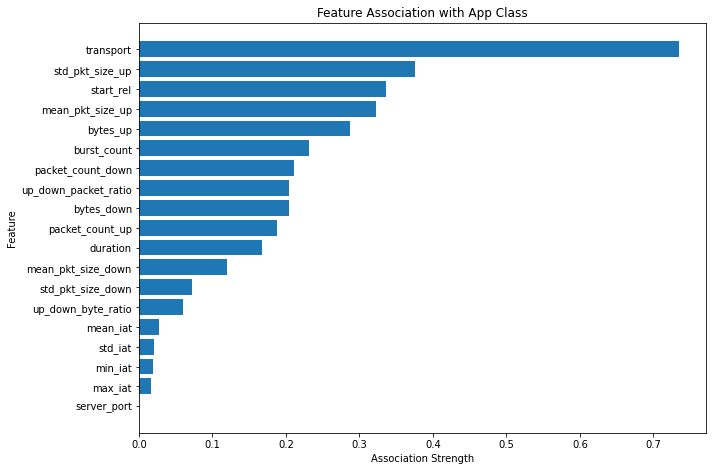

In [49]:
plot_df = results_df.sort_values('Association', ascending=True)
plt.figure(figsize=(10, max(5, len(plot_df) * 0.35)))
plt.barh(plot_df['Feature'], plot_df['Association'])
plt.xlabel('Association Strength')
plt.ylabel('Feature')
plt.title('Feature Association with App Class')
plt.tight_layout()
plt.show()

In [50]:
threshold = 0.1
low_association = results_df[results_df['Association'] < threshold]
high_association = results_df[results_df['Association'] > threshold]

print(f"Features with association < {threshold}:")
print(low_association['Feature'].tolist())

print(f"\nFeatures with association > {threshold}:")
print(high_association['Feature'].tolist())

Features with association < 0.1:
['std_pkt_size_down', 'up_down_byte_ratio', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'server_port']

Features with association > 0.1:
['transport', 'std_pkt_size_up', 'start_rel', 'mean_pkt_size_up', 'bytes_up', 'burst_count', 'packet_count_down', 'up_down_packet_ratio', 'bytes_down', 'packet_count_up', 'duration', 'mean_pkt_size_down']


In [51]:
numeric_temp_df = results_df[(results_df['Association'] > threshold) & (results_df['Type'] == 'Numeric')]
high_numeric_features = numeric_temp_df['Feature'].tolist()

categorical_temp_df = results_df[(results_df['Association'] > threshold) & (results_df['Type'] == 'Categorical')]
high_categorical_features = categorical_temp_df["Feature"].tolist()

print("Highly associated numeric features with the classes: \n", high_numeric_features)
print("Highly associated categorical features with the classes: \n", high_categorical_features)

Highly associated numeric features with the classes: 
 ['std_pkt_size_up', 'start_rel', 'mean_pkt_size_up', 'bytes_up', 'burst_count', 'packet_count_down', 'up_down_packet_ratio', 'bytes_down', 'packet_count_up', 'duration', 'mean_pkt_size_down']
Highly associated categorical features with the classes: 
 ['transport']


In [52]:
numeric_features =  results_df[results_df['Type'] == 'Numeric']["Feature"].tolist()
corr_matrix = X[numeric_features].corr(method='pearson')
corr_matrix

,std_pkt_size_up,start_rel,mean_pkt_size_up,bytes_up,burst_count,packet_count_down,up_down_packet_ratio,bytes_down,packet_count_up,duration,mean_pkt_size_down,std_pkt_size_down,up_down_byte_ratio,mean_iat,std_iat,min_iat,max_iat,server_port
std_pkt_size_up,1.000000,0.418353,0.533952,0.098721,0.017606,-0.101069,-0.204343,-0.107041,-0.074973,0.050063,0.090574,0.256813,0.133133,-0.058959,-0.019382,-0.124220,0.011934,NaN
start_rel,0.418353,1.000000,0.254173,0.034225,-0.069613,0.053976,-0.302976,0.053980,-0.015849,-0.035320,0.242723,0.163363,0.019607,0.007702,0.050813,-0.057028,0.062399,NaN
mean_pkt_size_up,0.533952,0.254173,1.000000,0.124675,0.026719,-0.075075,-0.184169,-0.079315,-0.052031,0.017056,0.056201,0.025978,0.449749,0.023627,-0.010026,0.265971,-0.044651,NaN
bytes_up,0.098721,0.034225,0.124675,1.000000,0.896178,0.516392,-0.161516,0.495021,0.773241,0.689034,0.109481,-0.175498,0.270573,-0.099886,-0.086107,-0.018028,0.035929,NaN
burst_count,0.017606,-0.069613,0.026719,0.896178,1.000000,0.506182,-0.195742,0.490108,0.843913,0.766560,0.096598,-0.184471,0.147729,-0.034270,-0.040535,-0.026421,0.067097,NaN
packet_count_down,-0.101069,0.053976,-0.075075,0.516392,0.506182,1.000000,-0.329587,0.999455,0.761169,0.419148,0.275457,-0.165386,-0.072558,-0.066810,-0.065243,-0.009697,0.022539,NaN
up_down_packet_ratio,-0.204343,-0.302976,-0.184169,-0.161516,-0.195742,-0.329587,1.000000,-0.328687,-0.322545,-0.145796,-0.586533,-0.092172,0.349163,0.083856,0.076842,0.020205,0.009781,NaN
bytes_down,-0.107041,0.053980,-0.079315,0.495021,0.490108,0.999455,-0.328687,1.000000,0.755142,0.404256,0.280128,-0.162873,-0.078707,-0.065427,-0.064395,-0.009240,0.019980,NaN
packet_count_up,-0.074973,-0.015849,-0.052031,0.773241,0.843913,0.761169,-0.322545,0.755142,1.000000,0.613855,0.296950,-0.172359,0.014499,-0.098865,-0.090518,-0.017889,0.025079,NaN
duration,0.050063,-0.035320,0.017056,0.689034,0.766560,0.419148,-0.145796,0.404256,0.613855,1.000000,-0.000091,-0.118806,0.131241,0.295221,0.289151,-0.034729,0.383986,NaN


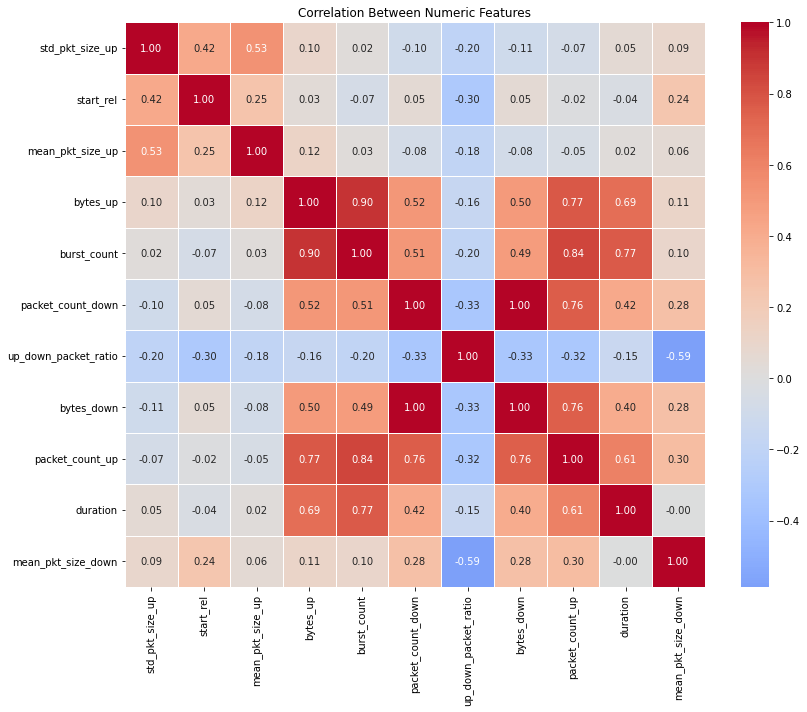

In [63]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', linewidths=0.5)
plt.title('Correlation Between Numeric Features')
plt.tight_layout()
plt.show()

In [64]:
import numpy as np

corr_matrix = X[high_numeric_features].corr()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = upper_triangle.stack().reset_index()
high_corr_pairs = high_corr_pairs.rename(columns={'level_0': 'Feature_1'})
high_corr_pairs = high_corr_pairs.rename(columns={'level_1': 'Feature_2'}) 
high_corr_pairs = high_corr_pairs.rename(columns={0: 'Correlation'})

high_corr_pairs = high_corr_pairs[high_corr_pairs['Correlation'].abs() > 0.8]
high_corr_pairs['Abs_Correlation'] = high_corr_pairs['Correlation'].abs()
high_corr_pairs = high_corr_pairs.sort_values('Abs_Correlation', ascending=False)

print(high_corr_pairs)

            Feature_1        Feature_2  Correlation  Abs_Correlation
41  packet_count_down       bytes_down     0.999455         0.999455
27           bytes_up      burst_count     0.896178         0.896178
37        burst_count  packet_count_up     0.843913         0.843913


In [65]:
import numpy as np

corr_threshold = 0.8
corr_matrix = X[high_numeric_features].corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

redundant_features = []
for column in upper_triangle.columns:
    if any(upper_triangle[column]>corr_threshold):
        redundant_features.append(column)

print("Features to remove:")
print(redundant_features)

selected_numeric_features = []
for f in numeric_features:
    if f not in redundant_features:
        selected_numeric_features.append(f)

print("\nFeatures retained:")
print(selected_numeric_features)

Features to remove:
['burst_count', 'bytes_down', 'packet_count_up']

Features retained:
['std_pkt_size_up', 'start_rel', 'mean_pkt_size_up', 'bytes_up', 'packet_count_down', 'up_down_packet_ratio', 'duration', 'mean_pkt_size_down', 'std_pkt_size_down', 'up_down_byte_ratio', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'server_port']


In [66]:
selected_features = results_df[results_df['Type'] == 'Categorical']["Feature"].tolist() + selected_numeric_features
print(f"Selected Features: \n{selected_features}\n")
print(f"Dropped Features because of cross-feature correlation (>0.8):\n{redundant_features}\n")
print(f"Features with less correlation with class label:\n{low_association['Feature'].tolist()}\n")

Selected Features: 
['transport', 'std_pkt_size_up', 'start_rel', 'mean_pkt_size_up', 'bytes_up', 'packet_count_down', 'up_down_packet_ratio', 'duration', 'mean_pkt_size_down', 'std_pkt_size_down', 'up_down_byte_ratio', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'server_port']

Dropped Features because of cross-feature correlation (>0.8):
['burst_count', 'bytes_down', 'packet_count_up']

Features with less correlation with class label:
['std_pkt_size_down', 'up_down_byte_ratio', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'server_port']



In [ ]:
# len((selected_features+redundant_features)) # Excluding class labels, flow_id, split (22-3 = 19)

### Distributions of the features and the data

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=training_data, x='app', order=training_data['app'].value_counts().index)
plt.title('Class Distribution')
plt.xlabel('App Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
class_distribution = pd.DataFrame({
    'Count': training_data['app'].value_counts(),
    'Percentage': training_data['app'].value_counts(normalize=True) * 100
})

print(class_distribution)

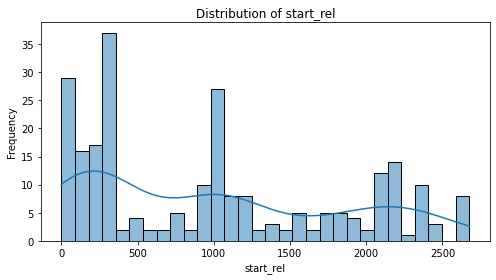

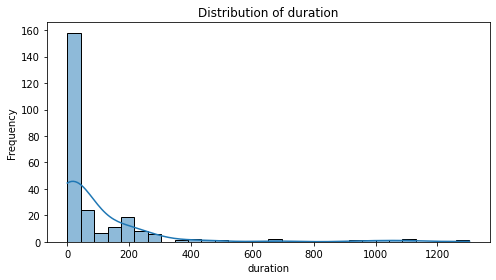

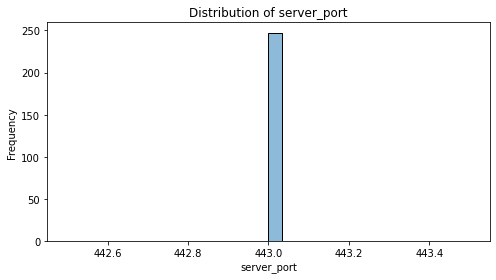

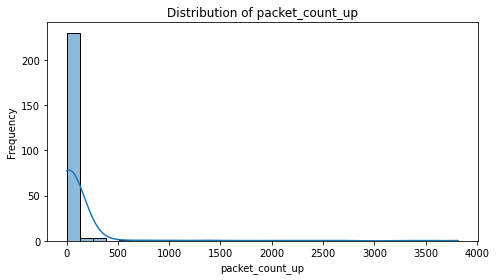

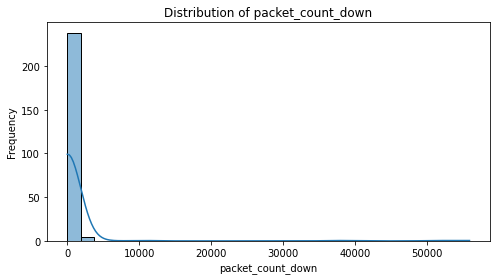

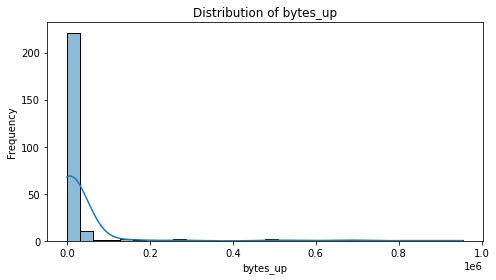

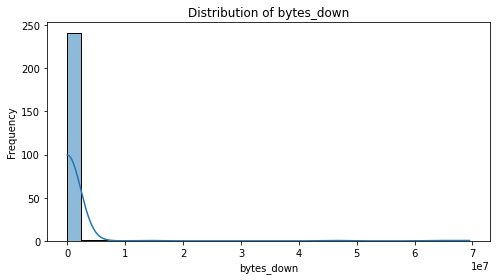

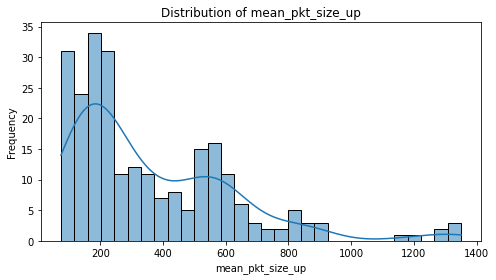

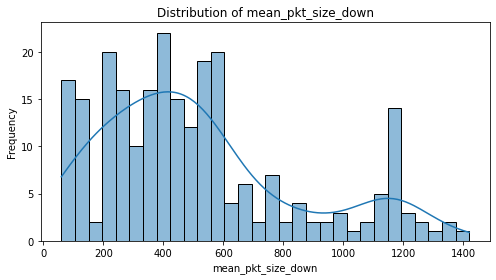

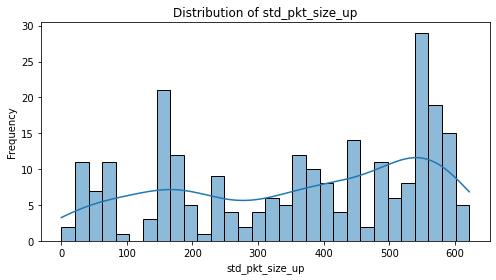

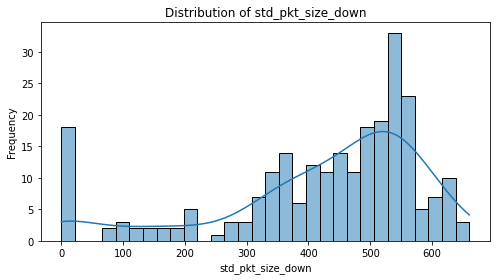

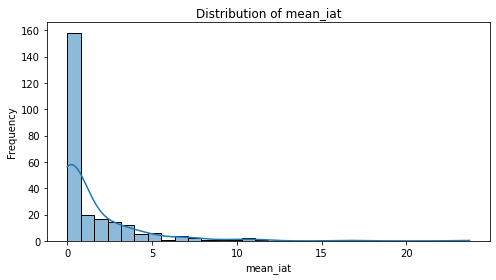

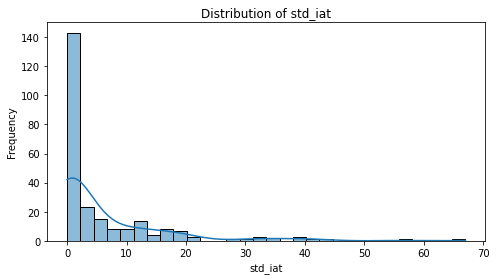

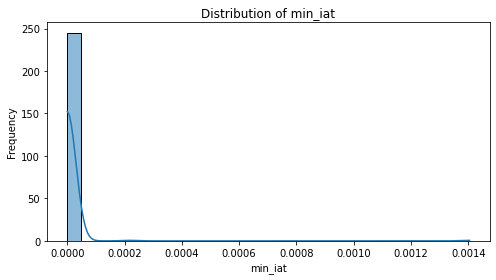

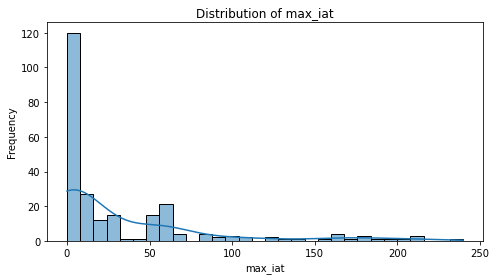

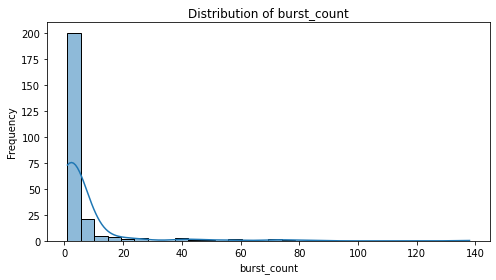

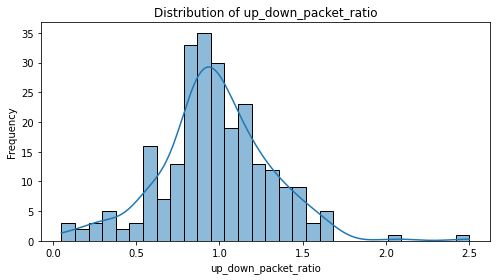

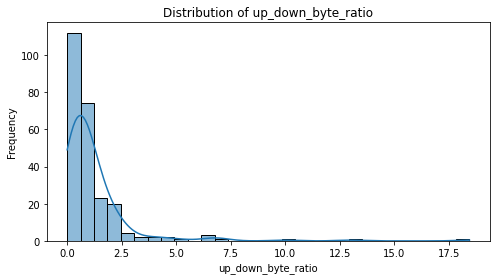

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_features = training_data.drop(columns=['app']).select_dtypes(include=np.number).columns

for feature in numeric_features:
    plt.figure(figsize=(7, 4))

    sns.histplot(training_data[feature].dropna(), kde=True, bins=30)

    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

In [16]:
import numpy as np
import pandas as pd

numeric_features = training_data.drop(columns=['app']).select_dtypes(include=np.number).columns

skewness = training_data[numeric_features].skew().sort_values(
    key=lambda x: x.abs(), ascending=False
)

print(skewness)

min_iat                 15.219646
packet_count_down        9.043591
bytes_down               9.040986
packet_count_up          5.951343
up_down_byte_ratio       5.496427
bytes_up                 5.252556
burst_count              5.118600
mean_iat                 3.846657
duration                 3.775887
std_iat                  2.715103
max_iat                  2.079710
mean_pkt_size_up         1.464675
std_pkt_size_down       -1.205967
mean_pkt_size_down       0.893498
start_rel                0.495907
std_pkt_size_up         -0.351287
up_down_packet_ratio     0.230112
server_port              0.000000
dtype: float64


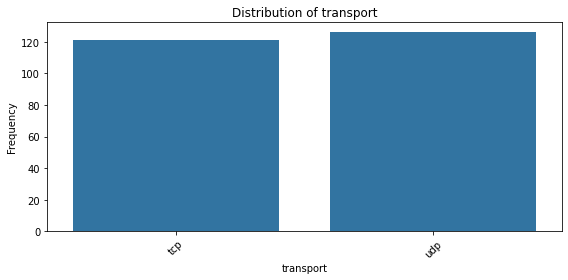

In [17]:
categorical_features = training_data.drop(columns=['app']).select_dtypes(exclude=np.number).columns

for feature in categorical_features:
    plt.figure(figsize=(8, 4))

    counts = training_data[feature].value_counts()
    sns.barplot(x=counts.index, y=counts.values)

    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [19]:
skew_df = pd.DataFrame({
    'Feature': skewness.index,
    'Skewness': skewness.values
})

skew_df['Skew_Category'] = np.where(
    skew_df['Skewness'] > 1, 'Highly Right-Skewed',
    np.where(
        skew_df['Skewness'] < -1, 'Highly Left-Skewed',
        np.where(
            skew_df['Skewness'].abs() <= 0.5, 'Approximately Symmetric',
            'Moderately Skewed'
        )
    )
)

skew_df

,Feature,Skewness,Skew_Category
0,min_iat,15.219646,Highly Right-Skewed
1,packet_count_down,9.043591,Highly Right-Skewed
2,bytes_down,9.040986,Highly Right-Skewed
3,packet_count_up,5.951343,Highly Right-Skewed
4,up_down_byte_ratio,5.496427,Highly Right-Skewed
5,bytes_up,5.252556,Highly Right-Skewed
6,burst_count,5.118600,Highly Right-Skewed
7,mean_iat,3.846657,Highly Right-Skewed
8,duration,3.775887,Highly Right-Skewed
9,std_iat,2.715103,Highly Right-Skewed


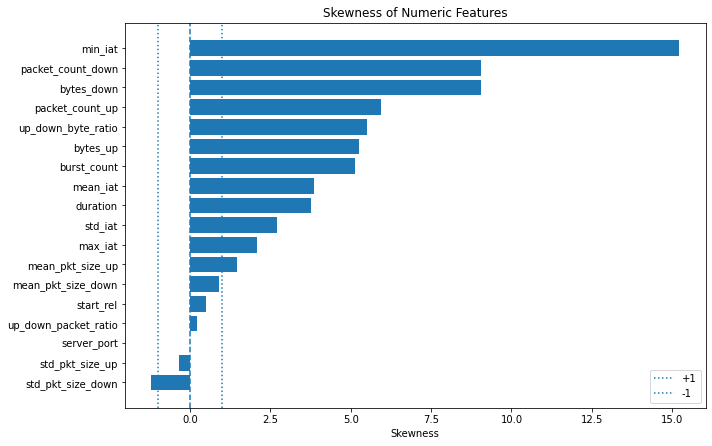

In [132]:
skew_plot = skew_df.sort_values('Skewness')
plt.figure(figsize=(10, max(5, len(skew_plot) * 0.35)))
plt.barh(skew_plot['Feature'], skew_plot['Skewness'])
plt.axvline(0, linestyle='--')
plt.axvline(1, linestyle=':', label='+1')
plt.axvline(-1, linestyle=':', label='-1')
plt.xlabel('Skewness')
plt.title('Skewness of Numeric Features')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Applying logarithmic transformation
skew_before = training_data[numeric_features].skew()

log_data = training_data[numeric_features].copy()

for feature in numeric_features:
    if (training_data[feature] >= 0).all():
        log_data[feature] = np.log1p(training_data[feature])

skew_after = log_data.skew()

skew_comparison = pd.DataFrame({
    'Skewness_Before': skew_before,
    'Skewness_After': skew_after
})

skew_comparison['Change'] = (
    skew_comparison['Skewness_Before'].abs() -
    skew_comparison['Skewness_After'].abs()
)

skew_comparison = skew_comparison.sort_values(
    'Skewness_Before', key=lambda x: x.abs(), ascending=False
)

skew_comparison

,Skewness_Before,Skewness_After,Change
min_iat,15.219646,15.219107,0.000539
packet_count_down,9.043591,2.535942,6.507649
bytes_down,9.040986,1.862309,7.178677
packet_count_up,5.951343,2.084872,3.866472
up_down_byte_ratio,5.496427,1.679373,3.817054
bytes_up,5.252556,1.324704,3.927852
burst_count,5.118600,1.716906,3.401693
mean_iat,3.846657,1.207169,2.639488
duration,3.775887,0.202464,3.573423
std_iat,2.715103,0.688849,2.026254


In [21]:
skew_comparison['Skew_Category'] = np.where(
    skew_comparison['Skewness_After'] > 1, 'Highly Right-Skewed',
    np.where(
        skew_comparison['Skewness_After'] < -1, 'Highly Left-Skewed',
        np.where(
            skew_comparison['Skewness_After'].abs() <= 0.5, 'Approximately Symmetric',
            'Moderately Skewed'
        )
    )
)

skew_comparison

,Skewness_Before,Skewness_After,Change,Skew_Category
min_iat,15.219646,15.219107,0.000539,Highly Right-Skewed
packet_count_down,9.043591,2.535942,6.507649,Highly Right-Skewed
bytes_down,9.040986,1.862309,7.178677,Highly Right-Skewed
packet_count_up,5.951343,2.084872,3.866472,Highly Right-Skewed
up_down_byte_ratio,5.496427,1.679373,3.817054,Highly Right-Skewed
bytes_up,5.252556,1.324704,3.927852,Highly Right-Skewed
burst_count,5.118600,1.716906,3.401693,Highly Right-Skewed
mean_iat,3.846657,1.207169,2.639488,Highly Right-Skewed
duration,3.775887,0.202464,3.573423,Approximately Symmetric
std_iat,2.715103,0.688849,2.026254,Moderately Skewed


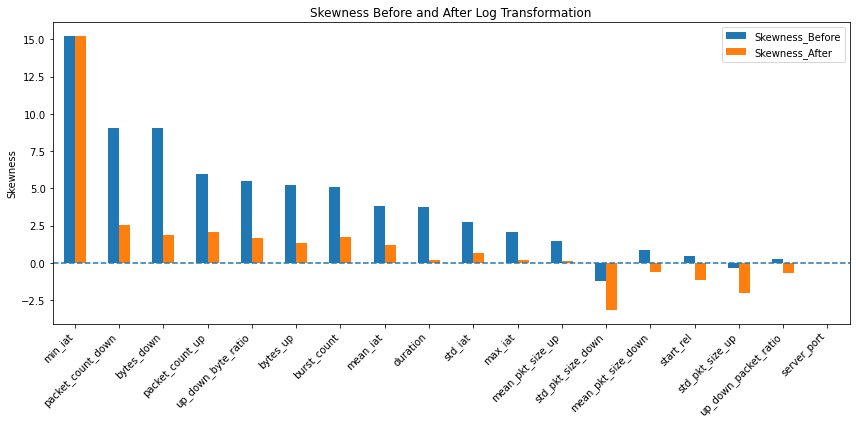

In [136]:
skew_comparison.plot(
    y=['Skewness_Before', 'Skewness_After'],
    kind='bar',
    figsize=(12, 6)
)

plt.axhline(0, linestyle='--')
plt.ylabel('Skewness')
plt.title('Skewness Before and After Log Transformation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()